### Top Rows

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# -------------------------------------------------
# 1. Replace "x" with 1800 in ORIGINAL df (in place)
# -------------------------------------------------

file_path = "results-filtered-dataset.csv"

# Read the first sheet
# df = pd.read_excel(file_path)
# df = pd.read_csv(file_path, sep=r"\s+")
df = pd.read_csv(file_path)

sp_noAltRB = ["UMKP-S", "UMKP-R", "UMKP-P"]
sp_AltRB = ["UMKP+-S", "UMKP+-R", "UMKP+-P"]
dense = ["kPEX", "kPEX-S", "kPEX-R", "kPEX-P"]

sparse = sp_AltRB + sp_noAltRB
all_algos = sparse + dense
# print(df.columns.tolist())
df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


In [6]:
df["sparse_min"] = df[sparse].min(axis=1)
df["dense_min"] = df[dense].min(axis=1)

df["ratio"] = np.maximum(df["sparse_min"], df["dense_min"]) / np.minimum(df["sparse_min"], df["dense_min"])

filtered_rows = df[
    (df["sparse_min"] > 1) &
    (df["dense_min"] > 1) &
    (df["ratio"] >= 10)
].sort_values(by="ratio", ascending=False).copy()

# Split into two tables
sparse_wins_table = filtered_rows[filtered_rows["sparse_min"] < filtered_rows["dense_min"]]
dense_wins_table  = filtered_rows[filtered_rows["dense_min"] < filtered_rows["sparse_min"]]

total = len(filtered_rows)

display(Markdown(f"""
## Experiment Summary
### Filtered rows: **{total}**
- Sparse faster: **{len(sparse_wins_table)}**
- Dense faster: **{len(dense_wins_table)}**
"""))

display(Markdown("## Sparse Wins"))
print(sparse_wins_table[["dataset", "k", "sparse_min", "dense_min", "ratio"]])

display(Markdown("## Dense Wins"))
print(dense_wins_table[["dataset", "k", "sparse_min", "dense_min", "ratio"]])


## Experiment Summary
### Filtered rows: **148**
- Sparse faster: **126**
- Dense faster: **22**


## Sparse Wins

                dataset     k  sparse_min  dense_min        ratio
2214       mult_dcop_03   8.0    1.424235  1800.0000  1263.836375
4040   TSOPF_RS_b678_c1  10.0    1.604391  1800.0000  1121.921028
4041   TSOPF_RS_b678_c1  20.0    1.891792  1800.0000   951.478810
4022  TSOPF_RS_b2383_c1  10.0    2.388061  1800.0000   753.749590
4023  TSOPF_RS_b2383_c1  20.0    2.443003  1800.0000   736.798113
...                 ...   ...         ...        ...          ...
1472                 G9   5.0    1.375400    15.2233    11.068271
2554         p-hat700-1   5.0  162.663300  1800.0000    11.065803
1473                 G9   6.0   20.932513   229.4209    10.960027
3977    TSOPF_FS_b39_c7   2.0    1.075077    11.5656    10.757927
2547         p-hat500-1   8.0  172.952600  1800.0000    10.407476

[126 rows x 5 columns]


## Dense Wins

                   dataset     k   sparse_min  dense_min       ratio
2954          san200-0-9-1   2.0  1800.000000     8.6660  207.708285
4324          wiki-topcats  20.0  1800.000000    11.2630  159.815325
516          bibsonomy-2ut  20.0   244.912000     2.4535   99.821480
4130         web-ClueWeb09  15.0  1417.348800    14.3025   99.097976
2037              MANN-a45  15.0  1800.000000    28.5184   63.117145
3712                  t520  20.0   222.937711     3.7555   59.362991
2066             Maragal_6  15.0  1800.000000    31.0583   57.955522
2067             Maragal_6  20.0  1800.000000    47.3466   38.017513
1878           lastfm_band   6.0  1800.000000    55.1463   32.640449
1367                    fp   2.0  1800.000000    59.3069   30.350600
4155  web-wikipedia-growth   5.0  1800.000000    64.9444   27.716016
1879           lastfm_band   7.0  1800.000000    72.9282   24.681810
1687                  hood  20.0    34.002900     1.3949   24.376586
443               bcsstk39  20.0  

### Winning Algorithm Counts

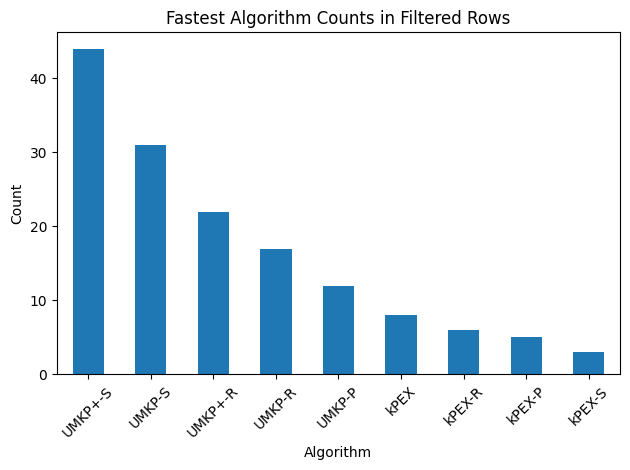

In [4]:
# algorithm that is fastest per row
filtered_rows["fastest_algo"] = filtered_rows[all_algos].idxmin(axis=1)

# count occurrences
algo_counts = filtered_rows["fastest_algo"].value_counts()

algo_counts.plot(kind="bar")

plt.xlabel("Algorithm")
plt.ylabel("Count")
plt.title("Fastest Algorithm Counts in Filtered Rows")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Varying Ratio Threshold

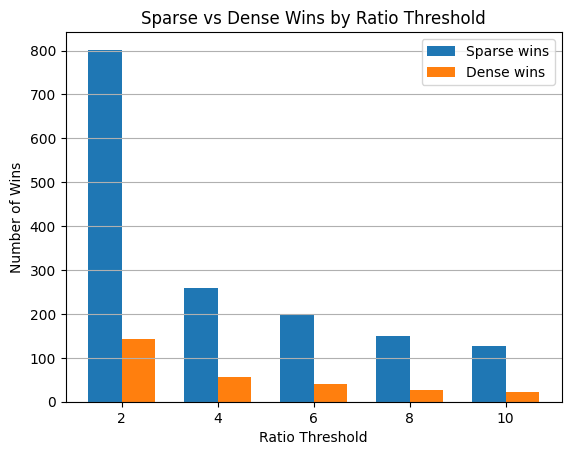

In [5]:
ratio_thresholds = [2, 4, 6, 8, 10]

sparse_wins_list = []
dense_wins_list = []

df["ratio"] = np.maximum(df["sparse_min"], df["dense_min"]) / np.minimum(df["sparse_min"], df["dense_min"])

for r in ratio_thresholds:
    filtered_rows = df[
        (df["sparse_min"] > 1) &
        (df["dense_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)
    sparse_wins = (filtered_rows["sparse_min"] < filtered_rows["dense_min"]).sum()
    dense_wins = total - sparse_wins

    sparse_wins_list.append(sparse_wins)
    dense_wins_list.append(dense_wins)

# Bar chart
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()
plt.bar(x - width/2, sparse_wins_list, width, label="Sparse wins")
plt.bar(x + width/2, dense_wins_list, width, label="Dense wins")

plt.xticks(x, ratio_thresholds)
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title("Sparse vs Dense Wins by Ratio Threshold")
plt.legend()
plt.grid(axis="y")

plt.show()